In [4]:
# TODO: Nothing I tried works. Just restart the notebook kernel when you change anything.

import sys
from pathlib import Path

# Ensure the notebook imports the local src tree, not an installed copy.
src_dir = Path.cwd() / "src"
if str(src_dir) in sys.path:
    sys.path.remove(str(src_dir))
sys.path.insert(0, str(src_dir))


# Reload to pick up latest changes
from importlib import reload

import data_labeling_pipeline as dlp

reload(dlp)
reload(dlp.hyperparameters)


# # Use the %load_ext autoreload magic command to enable automatic reloading.
# %load_ext autoreload
# # Use %autoreload 2 to specify that all modules should be reloaded before executing the Python code.
# %autoreload 2

<module 'data_labeling_pipeline.hyperparameters' from '/home/lmertens/git-repos/master-thesis-lmertens/data_labeling_pipeline/src/data_labeling_pipeline/hyperparameters.py'>

In [5]:
from data_labeling_pipeline.grandtour_missions import (
    get_mission_by_shortname,
)

mission_shortname = "ETH-2"
mission = get_mission_by_shortname(mission_shortname)

mission_path = (
    Path("/datahome/lmertens/grand_tour_dataset") / "ros1" / mission_shortname
)
assert mission_path.exists(), f"Mission path {mission_path} does not exist"

output_dir = Path("./output") / mission_shortname
output_dir.mkdir(parents=True, exist_ok=True)


In [6]:
from data_labeling_pipeline import DataLabelingPipeline

pipeline = DataLabelingPipeline(mission_path=mission_path)


pipeline.process_mission(output_dir=output_dir)

Using hyperparameters:
P_x=
[[1.5 0.  0. ]
 [0.  1.5 0. ]
 [0.  0.  1. ]]
P_m=
[[0.2 0.  0. ]
 [0.  0.2 0. ]
 [0.  0.  1.5]]
P_w=
[[1.2 0.  0. ]
 [0.  1.2 0. ]
 [0.  0.  1. ]]
N=10
STEP_SIZE=9
dt=0.1
Loading data from /datahome/lmertens/grand_tour_dataset/ros1/ETH-2 ...
Median dt: 0.050s, regular diffs: 5715/5738


ValueError: Odometry topic '/boxi/inertial_explorer/tc/odometry' not found in bag /datahome/lmertens/grand_tour_dataset/ros1/ETH-2/2024-10-01-11-47-44_cpt7_ie_tc.bag. Available topics: []

Median dt: 0.100s, regular diffs: 3872/3874
[0.46244757 0.44552275 0.435717   ... 0.32979416 0.3636566  0.40872779]
[0.25819121 0.25520964 0.26639254 ... 0.00493169 0.02000338 0.03094206]


/tmp/ipykernel_1734748/266729140.py:147: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(cmap_name)


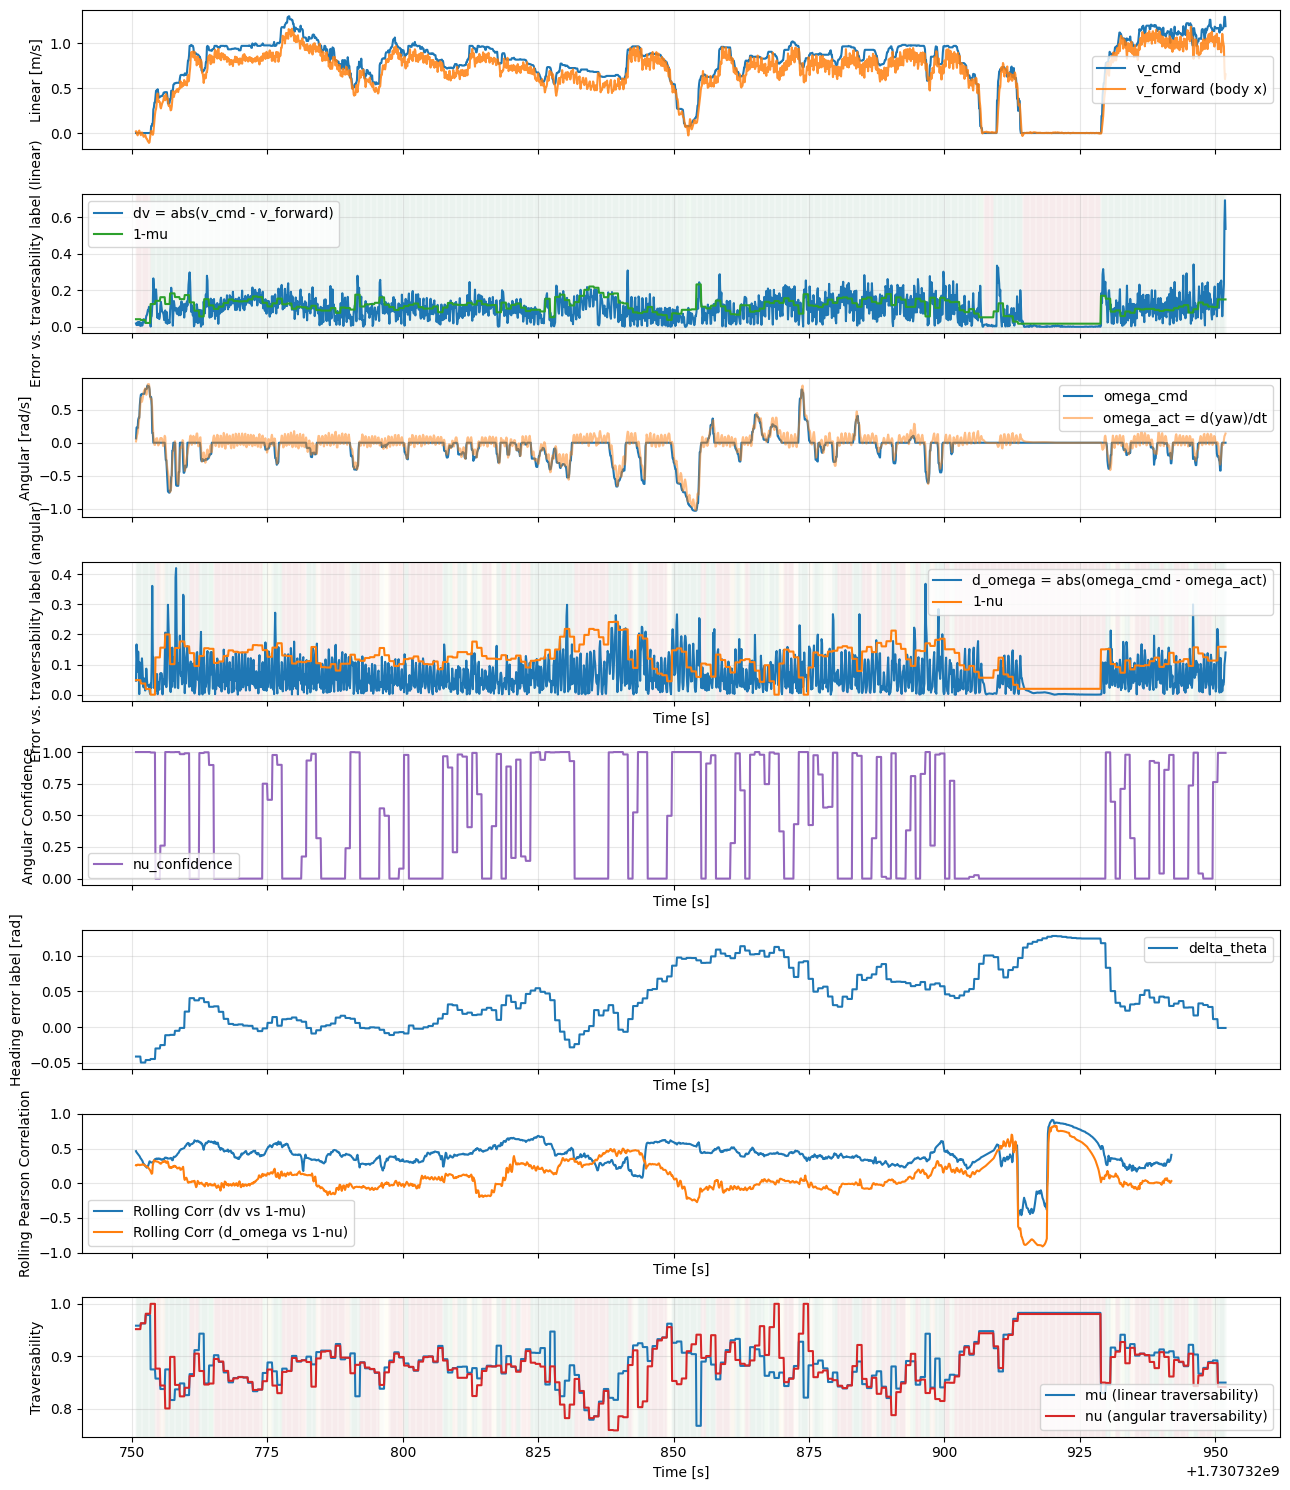

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from data_labeling_pipeline.dataset_loader import GrandTourLoader

# reload(GrandTourLoader)

loader = GrandTourLoader(mission_path)
shared_ts, U, Z = loader.load_data_shared_timestamps(dt=0.1, fill_gaps=True)


v_cmd, omega_cmd = U.T
px, py, yaw = Z.T
vx = np.gradient(px, shared_ts)
vy = np.gradient(py, shared_ts)
v_forward = np.cos(yaw) * vx + np.sin(yaw) * vy
omega_act = np.gradient(np.unwrap(yaw), shared_ts)

dv = np.abs(v_cmd - v_forward)
d_omega = np.abs(omega_cmd - omega_act)

# Load traversability labels and align to shared timeline
labels_dir = Path(f"./output/{Path(mission_path).name}")
label_ts = np.load(labels_dir / "timestamp.npy")
trav_labels = np.load(labels_dir / "trav_labels.npy")
nu_confidences = np.load(labels_dir / "nu_confidences.npy")

mu_label = trav_labels[:, 0]
nu_label = trav_labels[:, 1]
delta_theta_label = trav_labels[:, 2]


mu = np.interp(shared_ts, label_ts, mu_label)
nu = np.interp(shared_ts, label_ts, nu_label)
delta_theta = np.interp(shared_ts, label_ts, delta_theta_label)
nu_confidence = np.interp(shared_ts, label_ts, nu_confidences)

# Try to load mu_confidence
try:
    mu_confidences = np.load(labels_dir / "mu_confidences.npy")
    mu_confidence = np.interp(shared_ts, label_ts, mu_confidences)
except FileNotFoundError:
    # If not available, use all ones (perfect confidence)
    mu_confidence = np.ones_like(shared_ts)

fig, axes = plt.subplots(8, 1, figsize=(13, 15), sharex=True)

axes[0].plot(shared_ts, v_cmd, label="v_cmd")
axes[0].plot(shared_ts, v_forward, label="v_forward (body x)", alpha=0.85)
axes[0].set_ylabel("Linear [m/s]")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(shared_ts, dv, label="dv = abs(v_cmd - v_forward)")
axes[1].plot(shared_ts, 1 - mu, label="1-mu", color="tab:green")
axes[1].set_ylabel("Error vs. traversability label (linear)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(shared_ts, omega_cmd, label="omega_cmd")
axes[2].plot(shared_ts, omega_act, label="omega_act = d(yaw)/dt", alpha=0.5)
axes[2].set_ylabel("Angular [rad/s]")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

axes[3].plot(shared_ts, d_omega, label="d_omega = abs(omega_cmd - omega_act)")
axes[3].plot(shared_ts, 1 - nu, label="1-nu", color="tab:orange")
axes[3].set_ylabel("Error vs. traversability label (angular)")
axes[3].set_xlabel("Time [s]")
axes[3].legend()
axes[3].grid(True, alpha=0.3)

axes[4].plot(shared_ts, nu_confidence, label="nu_confidence", color="tab:purple")
axes[4].set_ylabel("Angular Confidence")
axes[4].set_xlabel("Time [s]")
axes[4].legend()
axes[4].grid(True, alpha=0.3)

axes[5].plot(shared_ts, delta_theta, label="delta_theta")
axes[5].set_ylabel("Heading error label [rad]")
axes[5].set_xlabel("Time [s]")
axes[5].legend()
axes[5].grid(True, alpha=0.3)

# axes[5].plot(shared_ts, yaw, label="yaw")
# axes[5].set_ylabel("Yaw [rad]")
# axes[5].set_xlabel("Time [s]")
# axes[5].legend()

# Plot the pearson correcelation with a rolling window
window_size = shared_ts.shape[0] - 1
window_size = 100


rolling_corr_v = np.array([
    np.corrcoef(dv[i : i + window_size], 1 - mu[i : i + window_size])[0, 1]
    for i in range(len(dv) - window_size)
])
rolling_corr_omega = np.array([
    np.corrcoef(d_omega[i : i + window_size], 1 - nu[i : i + window_size])[0, 1]
    for i in range(len(d_omega) - window_size)
])

print(rolling_corr_v)
print(rolling_corr_omega)
axes[6].plot(
    shared_ts[: len(rolling_corr_v)], rolling_corr_v, label="Rolling Corr (dv vs 1-mu)"
)
axes[6].plot(
    shared_ts[: len(rolling_corr_omega)],
    rolling_corr_omega,
    label="Rolling Corr (d_omega vs 1-nu)",
)
axes[6].set_ylabel("Rolling Pearson Correlation")
axes[6].set_xlabel("Time [s]")
axes[6].legend()
axes[6].grid(True, alpha=0.3)

axes[7].plot(shared_ts, mu, label="mu (linear traversability)", color="tab:blue")
axes[7].plot(shared_ts, nu, label="nu (angular traversability)", color="tab:red")
axes[7].set_ylabel("Traversability")
axes[7].set_xlabel("Time [s]")
axes[7].legend()
axes[7].grid(True, alpha=0.3)


# Add gradient shading based on confidence values (0=red, 0.5=orange, 1=green)
def add_confidence_shading(ax, time, confidence, cmap_name="RdYlGn"):
    """Add thin vertical lines colored by confidence values (0=red, 0.5=orange, 1=green)"""
    import matplotlib.cm as cm
    from matplotlib.collections import LineCollection
    from matplotlib.colors import Normalize

    # Get current y limits
    ylim = ax.get_ylim()

    # Prepare line segments
    segments = []
    colors_list = []

    for i in range(len(time)):
        segments.append([(time[i], ylim[0]), (time[i], ylim[1])])
        colors_list.append(confidence[i])

    # Create colormap
    cmap = cm.get_cmap(cmap_name)
    norm = Normalize(vmin=0, vmax=1)

    # Create line collection with very thin lines
    lc = LineCollection(
        segments, cmap=cmap, norm=norm, linewidths=0.05, zorder=-1, alpha=0.5
    )
    lc.set_array(np.array(colors_list))

    ax.add_collection(lc)
    ax.set_ylim(ylim)


# Add red shading where commands are near zero
def add_zero_shading(ax, time, condition, color="red", alpha=0.2):
    diff = np.diff(condition.astype(int))
    starts = np.where(diff == 1)[0] + 1
    ends = np.where(diff == -1)[0]
    if condition[0]:
        starts = np.concatenate([[0], starts])
    if condition[-1]:
        ends = np.concatenate([ends, [len(condition) - 1]])
    for s, e in zip(starts, ends):
        ax.axvspan(
            time[s],
            time[e],
            color=color,
            alpha=alpha,
        )


# Add confidence shading
add_confidence_shading(axes[1], shared_ts, mu_confidence, cmap_name="RdYlGn")
add_confidence_shading(axes[3], shared_ts, nu_confidence, cmap_name="RdYlGn")
add_confidence_shading(axes[7], shared_ts, nu_confidence, cmap_name="RdYlGn")


# Add zero command shading
# add_zero_shading(axes[1], shared_ts, np.isclose(v_cmd, 0))
# add_zero_shading(axes[3], shared_ts, np.isclose(omega_cmd, 0))
# add_zero_shading(axes[3], shared_ts, np.abs(omega_cmd) > 0.001, color="green")

fig.tight_layout()
plt.show()
